# Phase 3 — descriptive evidence integration
Three mouse immune-marker endpoints remain separate. These rankings are not validated T-cell-function predictions. See reports/scoring_spec.md for the frozen heuristic and exclusions.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
m=json.loads((ROOT/'results/phase3_manifest.json').read_text())
{k:m[k] for k in ['screen_genes','quantitative_records','qualitative_records','direct_T_function_eligible_records','predictive_gate']}

{'screen_genes': 11701,
 'quantitative_records': 35103,
 'qualitative_records': 6,
 'direct_T_function_eligible_records': 0,
 'predictive_gate': 'NO_GO'}

In [2]:
e=pd.read_parquet(ROOT/'data/curated/functional_evidence.parquet')
display(e.groupby(['endpoint_class','partition'],dropna=False).size().rename('records').to_frame())
display(pd.read_csv(ROOT/'results/phase3_coverage.csv'))

records
endpoint_class              partition                          
T_cell_function_qualitative development                       4
                            excluded_not_pristine_test        2
immune_marker_proxy         development                   35103

,endpoint,candidates,ranked,missing
0,CD40,6124,5155,969
1,MHCII,6124,5155,969
2,PDL1,6124,5155,969


In [3]:
display(pd.read_csv(ROOT/'results/phase3_qualitative_evidence.csv'))

,evidence_id,doi,accession,mouse_symbol,perturbation,perturbed_cell_type,organism,experimental_context,assay,outcome,...,compatibility_notes,source_location,split_group,mouse_gene_id,homology_class,gene_id,mapping_status,quantitative,endpoint_class,source_file
0,K10_GSK3B,10.7554/eLife.65110,NaN,Gsk3b,knockout,macrophage,Mus musculus,infection antigen presentation,intracellular cytokine flow,CD4 IFNg response,...,qualitative_only_stable_ID_and_numeric_values_...,Figure 6D-F,kiritsy_olive_2021,MGI:1861437,52446641.0,HGNC:4617,one_to_one,False,T_cell_function_qualitative,data/registry/perturbations.csv
1,K10_MED16,10.7554/eLife.65110,NaN,Med16,knockout,macrophage,Mus musculus,infection antigen presentation,intracellular cytokine flow,CD4 IFNg response,...,qualitative_only_stable_ID_and_numeric_values_...,Figure 6G-I,kiritsy_olive_2021,MGI:2158394,52447004.0,HGNC:17556,one_to_one,False,T_cell_function_qualitative,data/registry/perturbations.csv
2,K10_GSK3A,10.7554/eLife.65110,NaN,Gsk3a,knockout,macrophage,Mus musculus,infection antigen presentation,intracellular cytokine flow,CD4 IFNg response,...,not_a_verified_zero_effect_qualitative_only,Figure 6D-F,kiritsy_olive_2021,MGI:2152453,52448449.0,HGNC:4616,one_to_one,False,T_cell_function_qualitative,data/registry/perturbations.csv
3,K09_NDUFA1,10.7554/eLife.65109,NaN,Ndufa1,knockout,macrophage,Mus musculus,infection antigen presentation,intracellular cytokine flow,CD4 IFNg response,...,mixed_KO_control_ratios_not_independent_genes_...,Figure 7D-E,kiritsy_olive_2021,MGI:1929511,52456966.0,HGNC:7683,one_to_one,False,T_cell_function_qualitative,data/registry/perturbations.csv
4,M25_OLFR644,10.1038/s41590-025-02191-x,NaN,Olfr644,knockout,macrophage,Mus musculus,prostate tumor conditioned medium,CD8 proliferation,number of divisions,...,human_orthology_and_numeric_values_unverified,Figure 3h,marelli_2025,NaN,NaN,NaN,absent_from_snapshot,False,T_cell_function_qualitative,data/registry/perturbations.csv
5,M25_VMN2R29,10.1038/s41590-025-02191-x,NaN,Vmn2r29,knockout,macrophage,Mus musculus,prostate tumor conditioned medium,CD8 proliferation,number of divisions,...,human_orthology_and_numeric_values_unverified,Figure 3h,marelli_2025,MGI:1923479,52451970.0,NaN,ambiguous_class,False,T_cell_function_qualitative,data/registry/perturbations.csv


In [4]:
r=pd.read_csv(ROOT/'results/integrated_rankings.csv')
for endpoint,g in r.groupby('endpoint'):
    print(endpoint)
    display(g.dropna(subset=['rank']).head(10)[['gene_symbol','gene_id','rank','ranking_value','marker_selection_contrast','fdr','source_ids']])

CD40


,gene_symbol,gene_id,rank,ranking_value,marker_selection_contrast,fdr,source_ids
6124,SPTY2D1,HGNC:26818,1.0,0.989719,1.480990,0.988602,K09_SCREEN_CD40_Spty2d1
6125,UROD,HGNC:12591,2.0,0.987003,1.584500,0.989273,K09_SCREEN_CD40_Urod
6126,EGR2,HGNC:3239,3.0,0.986809,-1.292548,0.988602,K09_SCREEN_CD40_Egr2
6127,MESDC2,HGNC:13520,4.0,0.981377,1.210785,0.988602,K09_SCREEN_CD40_Mesd
6128,THAP4,HGNC:23187,5.0,0.980989,-1.169060,0.988602,K09_SCREEN_CD40_Thap4
6129,TBC1D4,HGNC:19165,6.0,0.978468,1.065810,0.424576,K09_SCREEN_CD40_Tbc1d4
6130,ECSIT,HGNC:29548,7.0,0.971872,-1.137660,0.989273,K09_SCREEN_CD40_Ecsit
6131,KIFC3,HGNC:6326,8.0,0.970999,0.963831,0.261329,K09_SCREEN_CD40_Kifc3
6132,GART,HGNC:4163,9.0,0.967798,2.099356,0.999966,K09_SCREEN_CD40_Gart
6133,QRICH1,HGNC:24713,10.0,0.964016,1.975420,0.999966,K09_SCREEN_CD40_Qrich1


MHCII


,gene_symbol,gene_id,rank,ranking_value,marker_selection_contrast,fdr,source_ids
0,EIF3F,HGNC:3275,1.0,0.996411,-1.921240,0.424576,K09_SCREEN_MHCII_Eif3f
1,USP5,HGNC:12628,2.0,0.993986,1.857460,0.863677,K09_SCREEN_MHCII_Usp5
2,DHX36,HGNC:14410,3.0,0.983899,-1.602470,0.989273,K09_SCREEN_MHCII_Dhx36
3,GLTSCR2,HGNC:4333,4.0,0.981668,-1.249390,0.069382,K09_SCREEN_MHCII_Nop53
4,GSK3B,HGNC:4617,5.0,0.979728,-1.274881,0.872695,K09_SCREEN_MHCII_Gsk3b
5,GCH1,HGNC:4193,6.0,0.979243,1.479900,0.989273,K09_SCREEN_MHCII_Gch1
6,DHPS,HGNC:2869,7.0,0.977304,-2.079160,0.999966,K09_SCREEN_MHCII_Dhps
7,RFWD2,HGNC:17440,8.0,0.973036,-1.653910,0.999966,K09_SCREEN_MHCII_Cop1
8,PAF1,HGNC:25459,9.0,0.972551,1.290206,0.989273,K09_SCREEN_MHCII_Paf1
9,SF3A2,HGNC:10766,10.0,0.971969,1.458040,0.999966,K09_SCREEN_MHCII_Sf3a2


PDL1


,gene_symbol,gene_id,rank,ranking_value,marker_selection_contrast,fdr,source_ids
12248,MAT2A,HGNC:6904,1.0,0.989137,1.553613,0.687686,K09_SCREEN_PDL1_Mat2a
12249,TRMT1,HGNC:25980,2.0,0.983414,1.781650,0.989273,K09_SCREEN_PDL1_Trmt1
12250,LAMTOR4,HGNC:33772,3.0,0.981765,1.864320,0.989273,K09_SCREEN_PDL1_Lamtor4
12251,NPRL3,HGNC:14124,4.0,0.979437,-1.318220,0.988602,K09_SCREEN_PDL1_Nprl3
12252,EIF3F,HGNC:3275,5.0,0.978274,-1.177380,0.424576,K09_SCREEN_PDL1_Eif3f
12253,EEPD1,HGNC:22223,6.0,0.976043,1.219610,0.988602,K09_SCREEN_PDL1_Eepd1
12254,RNF168,HGNC:26661,7.0,0.972939,1.333490,0.989273,K09_SCREEN_PDL1_Rnf168
12255,RIPK2,HGNC:10020,8.0,0.971872,1.156040,0.988602,K09_SCREEN_PDL1_Ripk2
12256,SRFBP1,HGNC:26333,9.0,0.971484,-1.509894,0.999966,K09_SCREEN_PDL1_Srfbp1
12257,LMBRD1,HGNC:23038,10.0,0.970320,1.124190,0.988602,K09_SCREEN_PDL1_Lmbrd1


,endpoint,transcriptomic_weight,rank_spearman,top20_overlap
0,CD40,0.25,0.874932,15
1,CD40,0.75,0.875328,13
2,MHCII,0.25,0.877885,14
3,MHCII,0.75,0.878198,13
4,PDL1,0.25,0.878758,14
5,PDL1,0.75,0.877173,15


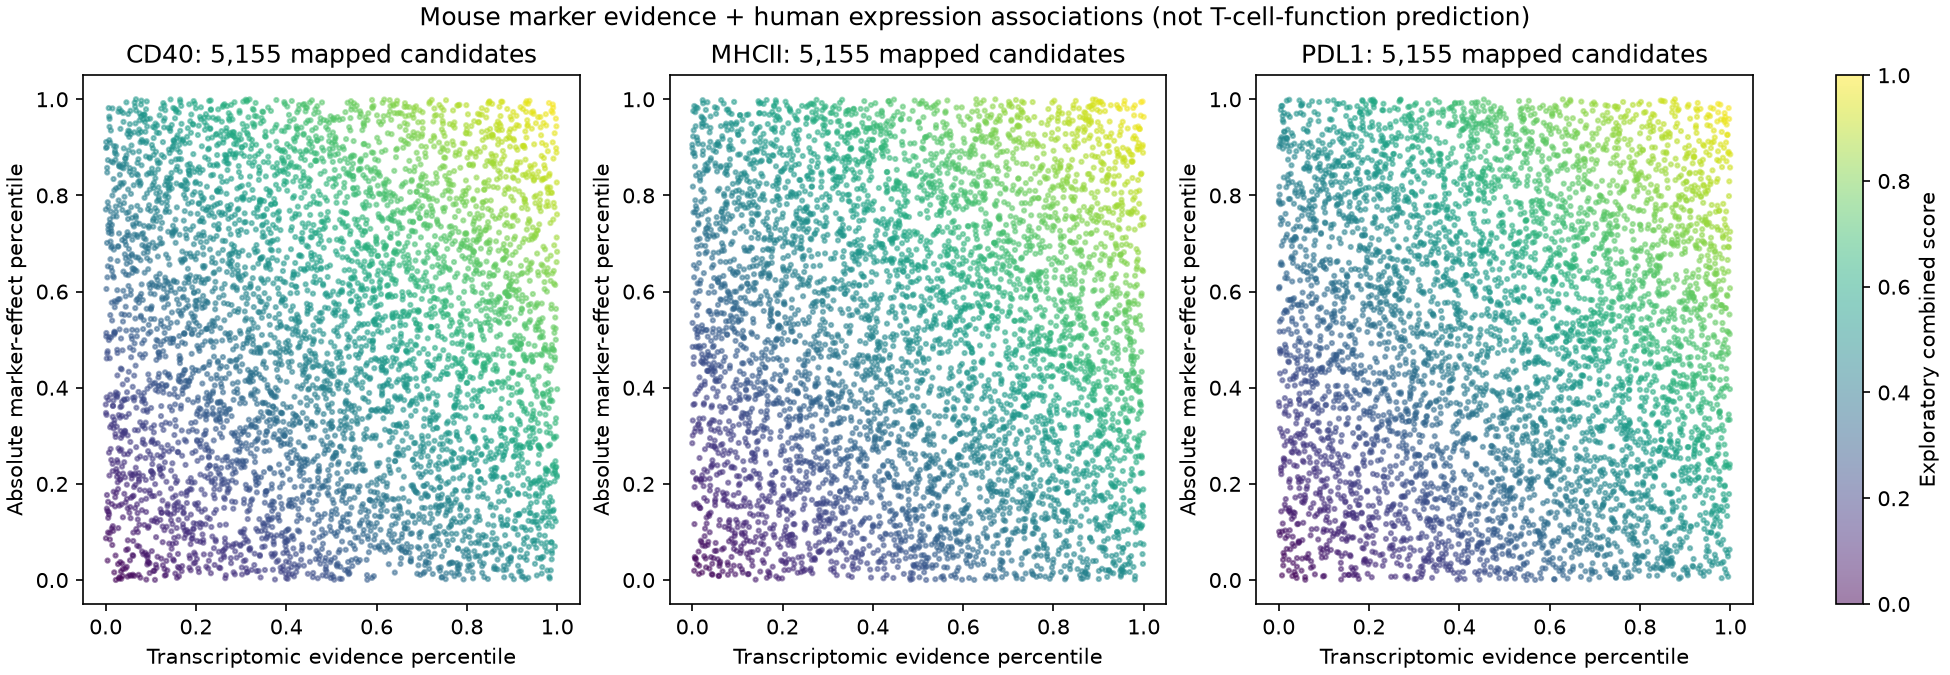

In [5]:
display(pd.read_csv(ROOT/'results/phase3_weight_sensitivity.csv'))
display(Image(filename=str(ROOT/'results/plots/phase3_evidence.png')))

In [6]:
# Reproduce only when deliberately enabled; outputs above are from the completed run.
RUN_PIPELINE=False
if RUN_PIPELINE:
    import subprocess,sys
    subprocess.run([sys.executable,str(ROOT/'phase3.py')],cwd=ROOT,check=True)

## Limits
One quantitative development family, mouse non-tumor context, immune-marker proxies, heuristic equal weighting, and unknown donor-level n. Unknown evidence is unranked, not negative. Six T-cell-function leads remain qualitative. No independent performance estimate is possible from this inventory.